In [1]:

import pandas as pd
import numpy as np

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    silhouette_score
)


In [2]:

# Load datasets
train = pd.read_csv("../training_image_features.csv")
test = pd.read_csv("../testing_image_features.csv")

TARGET = "Condition_Class"
CLASSES = ["Excellent", "Good", "Fair", "Poor"]

print("Training Dataset Shape:", train.shape)
print("Testing Dataset Shape:", test.shape)

print("\nTraining Dataset:")
display(train.head())


Training Dataset Shape: (10058, 43)
Testing Dataset Shape: (3224, 43)

Training Dataset:


,Sample_ID,Image_ID,Material_Type,Material_Subtype,Source,Exposure_Type,Crack_Level,Surface_Damage,Breakage_Level,Discoloration_Level,...,dark_pixel_ratio,bright_pixel_ratio,mean_hue,mean_saturation,saturation_std,contour_area,contour_perimeter,circularity,solidity,extent
0,TRAINING_00001,1.jpg,brick,Standard,Demolition_Site,Exterior_Weathered,5,4.0,3,High,...,0.007217,0.250679,16.328107,103.354121,34.788167,24050.0,2086.576892,0.069415,0.645430,0.460799
1,TRAINING_00002,1.jpg,concrete,Reinforced,Demolition_Site,Exterior_Weathered,5,3.5,2,Moderate,...,0.074190,0.022587,25.591271,61.989752,18.395387,15420.0,665.754394,0.437186,0.903736,0.635038
2,TRAINING_00003,1.jpg,tile,Standard,Demolition_Site,Exterior_Weathered,2,3.2,2,High,...,0.030780,0.677715,26.294677,69.389570,18.294682,25750.5,698.114786,0.663960,0.976915,0.710672
3,TRAINING_00004,1.jpg,brick,Standard,Demolition_Site,Exterior_Weathered,4,3.2,3,Moderate,...,0.230558,0.033828,41.511739,83.602221,28.279230,11908.5,1237.869180,0.097660,0.761900,0.616573
4,TRAINING_00005,1.jpg,concrete,Reinforced,Demolition_Site,Exterior_Weathered,5,4.0,3,High,...,0.136304,0.361647,29.703155,61.738122,22.880945,16204.5,963.702659,0.219260,0.837139,0.603520


In [3]:

# Exclude target-related scores
exclude = {
    "Condition_Score",
    "Damage_Score",
    "Alternative_Use_Suitability"
}

# Select numeric image features
features = [
    col for col in train.select_dtypes(include=np.number).columns
    if col not in exclude
]

print("Number of Original Features:", len(features))
print("\nSelected Features:")
print(features)


Number of Original Features: 26

Selected Features:
['Crack_Level', 'Surface_Damage', 'Breakage_Level', 'Deformation_Level', 'pixel_img_width', 'pixel_img_height', 'pixel_obj_width', 'pixel_obj_height', 'relative_area', 'edge_density', 'fill_ratio', 'color_std', 'mean_brightness', 'std_brightness', 'contrast', 'texture_laplacian_var', 'dark_pixel_ratio', 'bright_pixel_ratio', 'mean_hue', 'mean_saturation', 'saturation_std', 'contour_area', 'contour_perimeter', 'circularity', 'solidity', 'extent']


In [4]:

# Extract selected features
X_train = train[features].replace([np.inf, -np.inf], np.nan)
X_test = test[features].replace([np.inf, -np.inf], np.nan)

# Handle missing values
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Standardize features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Original Training Data Shape:", X_train.shape)
print("Original Testing Data Shape:", X_test.shape)
print("Preprocessing Completed Successfully")


Original Training Data Shape: (10058, 26)
Original Testing Data Shape: (3224, 26)
Preprocessing Completed Successfully


In [5]:

# Initialize PCA
pca = PCA(
    n_components=0.95,
    svd_solver="full"
)

# Fit PCA on training data
X_train_pca = pca.fit_transform(X_train)

# Transform testing data
X_test_pca = pca.transform(X_test)

print("PCA Transformation Completed")

print("\nOriginal Number of Features:", X_train.shape[1])

print("Reduced Number of Features:", X_train_pca.shape[1])

print("\nTraining PCA Shape:", X_train_pca.shape)
print("Testing PCA Shape:", X_test_pca.shape)

print(
    "\nTotal Explained Variance:",
    pca.explained_variance_ratio_.sum()
)


PCA Transformation Completed

Original Number of Features: 26
Reduced Number of Features: 13

Training PCA Shape: (10058, 13)
Testing PCA Shape: (3224, 13)

Total Explained Variance: 0.9530130661871932


In [6]:

# Calculate explained variance
explained_variance = pca.explained_variance_ratio_

variance_table = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    "Explained Variance": explained_variance,
    "Cumulative Variance": np.cumsum(explained_variance)
})

display(variance_table)

print(
    "Total Variance Retained:",
    round(np.sum(explained_variance) * 100, 2),
    "%"
)


,Principal Component,Explained Variance,Cumulative Variance
0,PC1,0.265148,0.265148
1,PC2,0.193934,0.459082
2,PC3,0.139114,0.598195
3,PC4,0.084862,0.683057
4,PC5,0.066794,0.749851
5,PC6,0.046416,0.796267
6,PC7,0.039623,0.835890
7,PC8,0.028512,0.864402
8,PC9,0.024521,0.888923
9,PC10,0.020471,0.909394


Total Variance Retained: 95.3 %


In [7]:

# Initialize K-Means on PCA-reduced data
model = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Fit model on PCA training data
train_clusters = model.fit_predict(X_train_pca)

# Predict testing clusters
test_clusters = model.predict(X_test_pca)

print("PCA-Based Clustering Completed")

print("\nCluster Distribution:")
print(pd.Series(train_clusters).value_counts().sort_index())


PCA-Based Clustering Completed

Cluster Distribution:
0    2500
1    3611
2    1017
3    2930
Name: count, dtype: int64


In [8]:

# Map clusters to majority condition classes
cluster_mapping = {}

for cluster in range(4):
    labels = train.loc[
        train_clusters == cluster, TARGET
    ]

    if len(labels) > 0:
        cluster_mapping[cluster] = labels.mode().iloc[0]
    else:
        cluster_mapping[cluster] = train[TARGET].mode().iloc[0]

print("Cluster to Condition Mapping:")
print(cluster_mapping)


Cluster to Condition Mapping:
{0: 'Fair', 1: 'Fair', 2: 'Fair', 3: 'Fair'}


In [9]:

# Predict testing classes
y_pred = np.array([
    cluster_mapping[c] for c in test_clusters
])

y_test = test[TARGET].astype(str)

print("Predicted Classes:")
print(pd.Series(y_pred).value_counts())

print("\nActual Classes:")
print(y_test.value_counts())


Predicted Classes:
Fair    3224
Name: count, dtype: int64

Actual Classes:
Condition_Class
Fair         2193
Good          716
Poor          274
Excellent      41
Name: count, dtype: int64


In [10]:

# Evaluate PCA-based clustering
print("Principal Component Analysis with K-Means")

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred)
)

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred,
    labels=CLASSES,
    zero_division=0
))

# Evaluate cluster separation
silhouette = silhouette_score(
    X_train_pca,
    train_clusters,
    sample_size=2000,
    random_state=42
)

print("Silhouette Score:", silhouette)

print(
    "Total Explained Variance:",
    pca.explained_variance_ratio_.sum()
)

print("Number of Principal Components:", pca.n_components_)


Principal Component Analysis with K-Means
Accuracy: 0.6802109181141439

Classification Report:
              precision    recall  f1-score   support

   Excellent       0.00      0.00      0.00        41
        Good       0.00      0.00      0.00       716
        Fair       0.68      1.00      0.81      2193
        Poor       0.00      0.00      0.00       274

    accuracy                           0.68      3224
   macro avg       0.17      0.25      0.20      3224
weighted avg       0.46      0.68      0.55      3224

Silhouette Score: 0.1751025142409257
Total Explained Variance: 0.9530130661871932
Number of Principal Components: 13


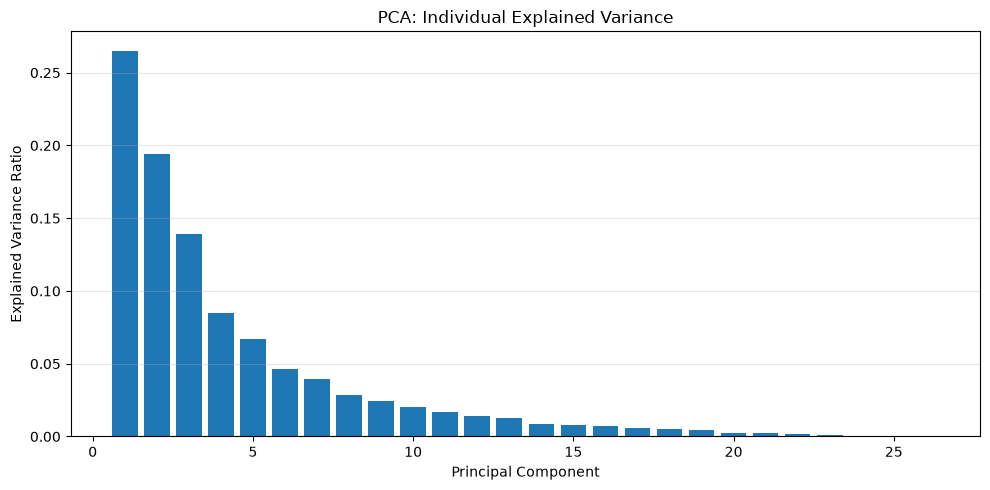

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

train_graph = pd.read_csv("../training_image_features.csv")

excluded = [
    "Condition_Class", "Condition_Score",
    "Damage_Score", "Alternative_Use_Suitability"
]

features = [
    c for c in train_graph.select_dtypes(include=np.number).columns
    if c not in excluded
]

X = train_graph[features].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

pca_model = PCA()
pca_model.fit(X)

explained_variance = pca_model.explained_variance_ratio_

plt.figure(figsize=(10, 5))
plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance
)

plt.title("PCA: Individual Explained Variance")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


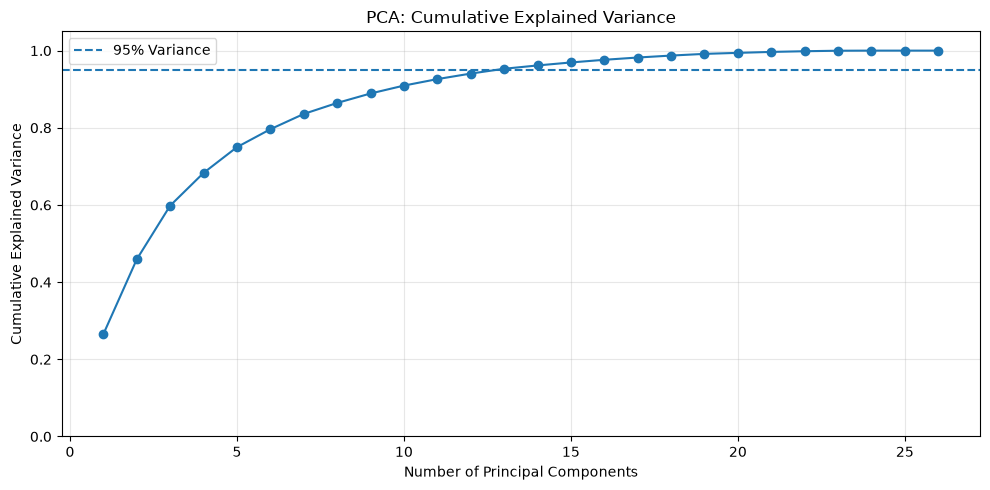

Components required for 95% variance: 13


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

train_graph = pd.read_csv("../training_image_features.csv")

excluded = [
    "Condition_Class", "Condition_Score",
    "Damage_Score", "Alternative_Use_Suitability"
]

features = [
    c for c in train_graph.select_dtypes(include=np.number).columns
    if c not in excluded
]

X = train_graph[features].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

pca_model = PCA()
pca_model.fit(X)

cumulative_variance = np.cumsum(
    pca_model.explained_variance_ratio_
)

plt.figure(figsize=(10, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% Variance"
)

plt.title("PCA: Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print("Components required for 95% variance:", components_95)


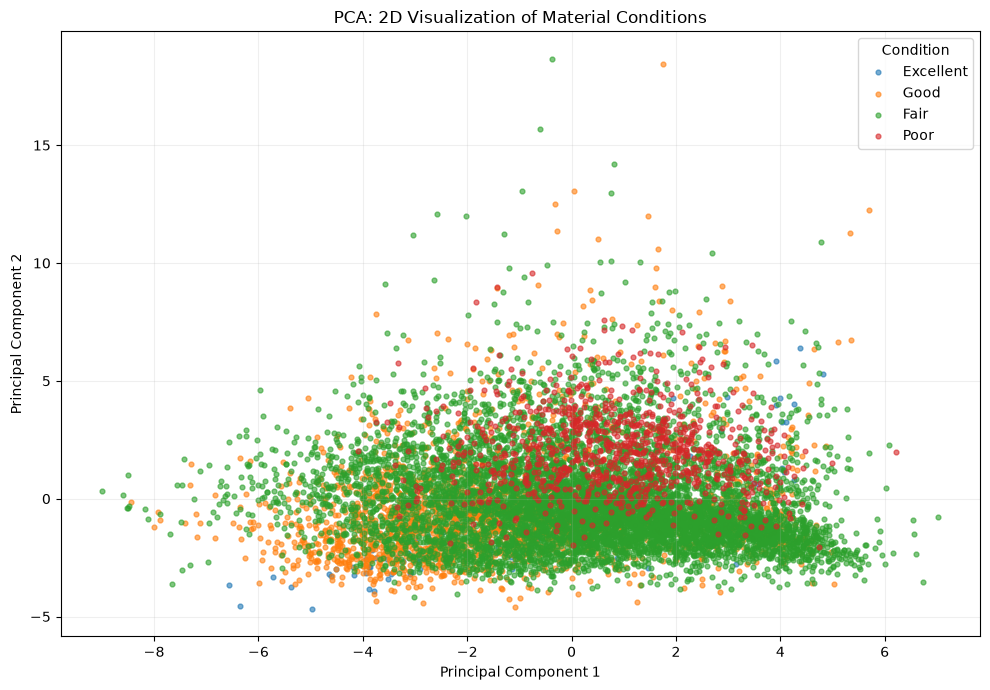

Explained variance: 0.4591


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

train_graph = pd.read_csv("../training_image_features.csv")

excluded = [
    "Condition_Class", "Condition_Score",
    "Damage_Score", "Alternative_Use_Suitability"
]

features = [
    c for c in train_graph.select_dtypes(include=np.number).columns
    if c not in excluded
]

X = train_graph[features].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

pca_model = PCA(n_components=2)
X_2d = pca_model.fit_transform(X)

classes = ["Excellent", "Good", "Fair", "Poor"]
y = train_graph["Condition_Class"].reset_index(drop=True)

plt.figure(figsize=(10, 7))

for condition in classes:
    mask = (y == condition).to_numpy()

    plt.scatter(
        X_2d[mask, 0],
        X_2d[mask, 1],
        label=condition,
        s=12,
        alpha=0.6
    )

plt.title("PCA: 2D Visualization of Material Conditions")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Condition")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    "Explained variance:",
    round(sum(pca_model.explained_variance_ratio_), 4)
)


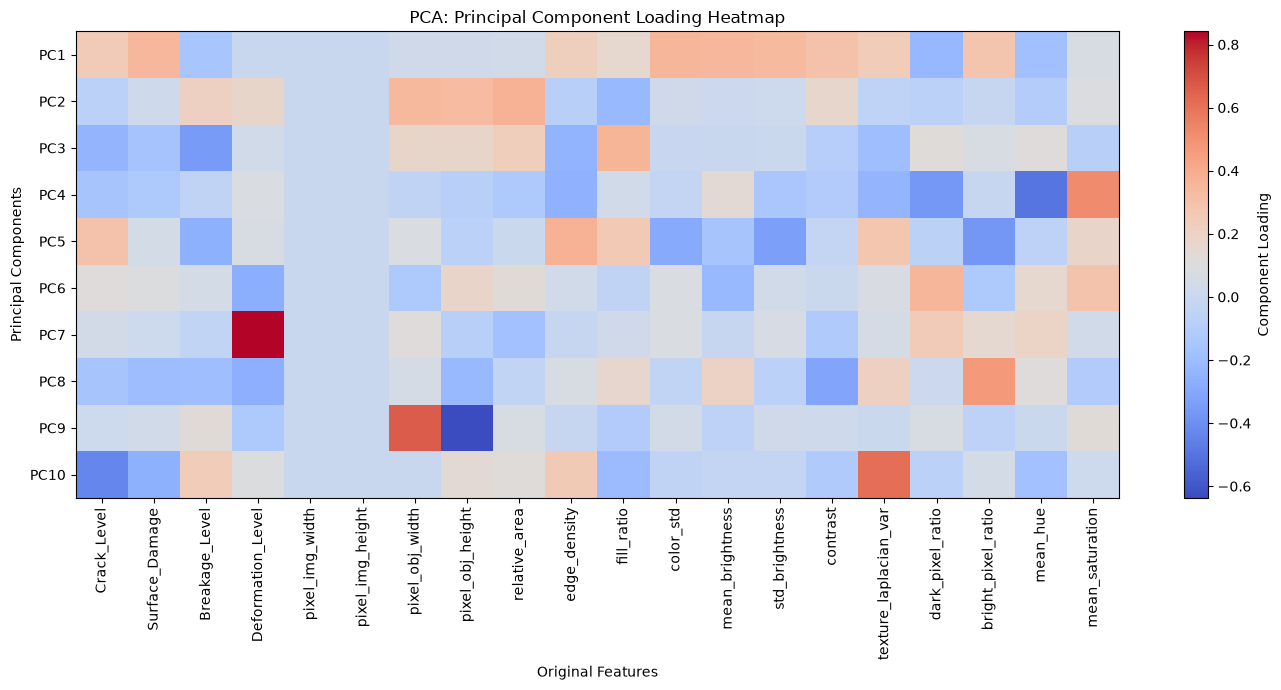

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

train_graph = pd.read_csv("../training_image_features.csv")

excluded = [
    "Condition_Class", "Condition_Score",
    "Damage_Score", "Alternative_Use_Suitability"
]

features = [
    c for c in train_graph.select_dtypes(include=np.number).columns
    if c not in excluded
]

X = train_graph[features].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

pca_model = PCA()
pca_model.fit(X)

number_of_components = min(10, pca_model.components_.shape[0])
number_of_features = min(20, len(features))

plt.figure(figsize=(14, 7))

plt.imshow(
    pca_model.components_[
        :number_of_components, :number_of_features
    ],
    aspect="auto",
    cmap="coolwarm"
)

plt.colorbar(label="Component Loading")

plt.xticks(
    range(number_of_features),
    features[:number_of_features],
    rotation=90
)

plt.yticks(
    range(number_of_components),
    [f"PC{i+1}" for i in range(number_of_components)]
)

plt.title("PCA: Principal Component Loading Heatmap")
plt.xlabel("Original Features")
plt.ylabel("Principal Components")
plt.tight_layout()
plt.show()
